Upload your car-price CSV dataset.
If you do not have it, cancel the upload to use a sample dataset.


Saving car data.csv to car data.csv

Dataset shape: (301, 9)
  Car_Name  Year  Selling_Price  Present_Price  Driven_kms Fuel_Type  \
0     ritz  2014           3.35           5.59       27000    Petrol   
1      sx4  2013           4.75           9.54       43000    Diesel   
2     ciaz  2017           7.25           9.85        6900    Petrol   
3  wagon r  2011           2.85           4.15        5200    Petrol   
4    swift  2014           4.60           6.87       42450    Diesel   

  Selling_type Transmission  Owner  
0       Dealer       Manual      0  
1       Dealer       Manual      0  
2       Dealer       Manual      0  
3       Dealer       Manual      0  
4       Dealer       Manual      0  

--- MODEL EVALUATION ---
Mean Absolute Error (MAE): 0.60
Root Mean Squared Error:   0.89
R-squared (R²):            0.966


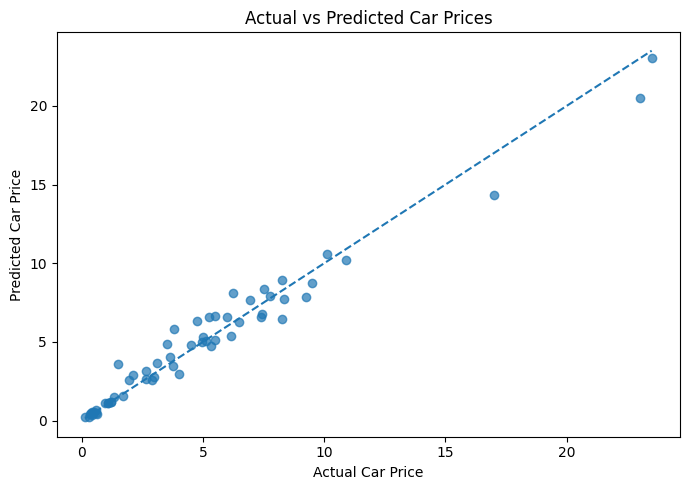


Top important features:
                             Feature  Importance
              numeric__present_price    0.872440
                       numeric__year    0.059230
                 numeric__driven_kms    0.032512
 categorical__transmission_Automatic    0.008081
      categorical__car_name_fortuner    0.004576
          categorical__car_name_city    0.003538
  categorical__car_name_land cruiser    0.003374
       categorical__fuel_type_Diesel    0.003166
    categorical__transmission_Manual    0.002522
 categorical__car_name_corolla altis    0.002171
        categorical__car_name_innova    0.002009
categorical__selling_type_Individual    0.001197
       categorical__fuel_type_Petrol    0.001076
    categorical__selling_type_Dealer    0.000659
         categorical__car_name_verna    0.000606


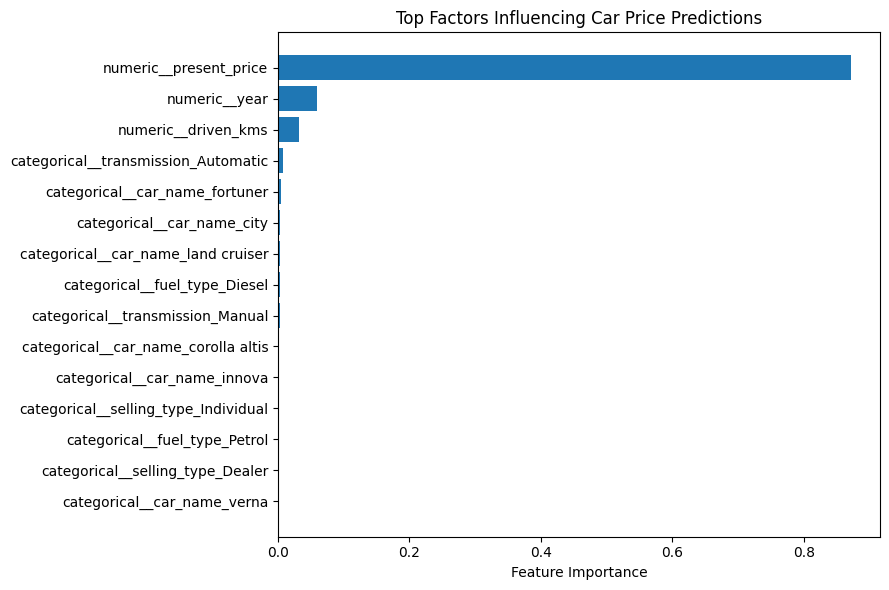


Task 3 completed!
Saved: car_price_predictions.csv
Saved: car_feature_importance.csv
Saved: model_report.txt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:

# CodeAlpha Internship - Task 3
# Car Price Prediction using Machine Learning

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from google.colab import files

# --------------------------------------------------
# 1. Load the car dataset
# Upload your internship CSV if available.
# Otherwise, use the public Automobile dataset.
# --------------------------------------------------

print("Upload your car-price CSV dataset.")
print("If you do not have it, cancel the upload to use a sample dataset.")

uploaded = files.upload()

if uploaded:
    csv_files = [f for f in uploaded if f.lower().endswith(".csv")]
    if not csv_files:
        raise ValueError("Please upload a CSV file.")
    df = pd.read_csv(csv_files[0])
else:
    print("Loading public Automobile dataset...")
    bunch = fetch_openml(
        name=" 자동차",
        version=1,
        as_frame=True
    )
    df = bunch.frame.copy()

print("\nDataset shape:", df.shape)
print(df.head())

# --------------------------------------------------
# 2. Clean column names and identify target
# --------------------------------------------------

df.columns = df.columns.str.strip().str.lower()

possible_targets = [
    "selling_price", "selling price", "price",
    "sellingprice", "msrp"
]

target = next(
    (col for col in possible_targets if col in df.columns),
    None
)

if target is None:
    raise ValueError(
        "Could not identify the target price column. "
        "Rename your target column to 'selling_price' or 'price'."
    )

# Remove rows with missing target values
df[target] = pd.to_numeric(df[target], errors="coerce")
df = df.dropna(subset=[target])
df = df[df[target] > 0]

# Drop columns that are identifiers or usually unhelpful
drop_cols = [
    col for col in df.columns
    if col in ["car_id", "id", "unnamed: 0", "vin"]
]
df = df.drop(columns=drop_cols, errors="ignore")

# Convert numeric-looking object columns when appropriate
for col in df.columns:
    if col == target:
        continue
    if df[col].dtype == "object":
        converted = pd.to_numeric(
            df[col].astype(str).str.replace(",", "", regex=False),
            errors="coerce"
        )
        if converted.notna().mean() > 0.8:
            df[col] = converted

X = df.drop(columns=[target])
y = df[target]

# Remove completely empty features
X = X.dropna(axis=1, how="all")

if len(X) < 10:
    raise ValueError("The dataset needs at least 10 valid rows.")

# --------------------------------------------------
# 3. Prepare numeric and categorical features
# --------------------------------------------------

numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=["number"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# --------------------------------------------------
# 4. Split dataset and train model
# --------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = Pipeline([
    ("preprocessing", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=150,
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)

# --------------------------------------------------
# 5. Evaluate model
# --------------------------------------------------

predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("\n--- MODEL EVALUATION ---")
print(f"Mean Absolute Error (MAE): {mae:,.2f}")
print(f"Root Mean Squared Error:   {rmse:,.2f}")
print(f"R-squared (R²):            {r2:.3f}")

# --------------------------------------------------
# 6. Compare actual and predicted prices
# --------------------------------------------------

plt.figure(figsize=(7, 5))
plt.scatter(y_test, predictions, alpha=0.7)
plt.xlabel("Actual Car Price")
plt.ylabel("Predicted Car Price")
plt.title("Actual vs Predicted Car Prices")

low = min(y_test.min(), predictions.min())
high = max(y_test.max(), predictions.max())
plt.plot([low, high], [low, high], linestyle="--")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 7. Feature importance for Random Forest
# --------------------------------------------------

feature_names = model.named_steps[
    "preprocessing"
].get_feature_names_out()

importances = model.named_steps[
    "regressor"
].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False).head(15)

print("\nTop important features:")
print(importance_df.to_string(index=False))

plt.figure(figsize=(9, 6))
plt.barh(
    importance_df["Feature"][::-1],
    importance_df["Importance"][::-1]
)
plt.xlabel("Feature Importance")
plt.title("Top Factors Influencing Car Price Predictions")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 8. Save results
# --------------------------------------------------

results = X_test.copy()
results["Actual_Price"] = y_test
results["Predicted_Price"] = predictions
results["Absolute_Error"] = abs(
    results["Actual_Price"] - results["Predicted_Price"]
)

results.to_csv("car_price_predictions.csv", index=False)
importance_df.to_csv("car_feature_importance.csv", index=False)

with open("model_report.txt", "w") as f:
    f.write("CodeAlpha Task 3: Car Price Prediction\n")
    f.write(f"Training rows: {len(X_train)}\n")
    f.write(f"Testing rows: {len(X_test)}\n")
    f.write(f"MAE: {mae:.4f}\n")
    f.write(f"RMSE: {rmse:.4f}\n")
    f.write(f"R2: {r2:.4f}\n")

print("\nTask 3 completed!")
print("Saved: car_price_predictions.csv")
print("Saved: car_feature_importance.csv")
print("Saved: model_report.txt")

files.download("car_price_predictions.csv")
files.download("car_feature_importance.csv")
files.download("model_report.txt")
